# BƯỚC 3: THUẬT TOÁN K-MEANS THUẦN TỪ ĐẦU (TASK 3: K-MEANS FROM SCRATCH)

Thực hiện tự lập trình K-Means bằng `NumPy` theo 4 bước cốt lõi:
1. **Khởi tạo (Initialize):** Chọn ngẫu nhiên $K$ tâm màu phân biệt.
2. **Gán cụm (Assign):** Gán từng điểm ảnh theo khoảng cách Euclidean bình phương nhỏ nhất.
3. **Cập nhật (Update):** Tính trung bình cộng các điểm ảnh trong cụm (xử lý cụm rỗng bằng điểm xa nhất).
4. **Lặp lại (Repeat):** Dừng khi độ dịch chuyển tâm $\le \text{tol}$ hoặc đạt `max_iter`.

> **Lưu ý:** Kết quả hội tụ và ảnh phân đoạn baseline được lưu trực tiếp trong notebook này.

### 1. Nạp module và chuẩn bị dữ liệu đầu vào độc lập

In [1]:
import io
import sys
from pathlib import Path

import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import Image, display

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import BASELINE_K, DEFAULT_IMAGE_PATH, FIGURE_DPI, MAX_ITER, RANDOM_SEED, TARGET_SIZE, TOLERANCE
from src.data.loader import load_image
from src.data.preprocessing import flatten_pixels, resize_image
from src.models.kmeans_scratch import KMeansFromScratch
from src.segmentation.segmenter import ImageSegmenter

def show_figure(fig):
    """Hiển thị trực tiếp đối tượng matplotlib Figure dưới dạng PNG ngay trong notebook."""
    buf = io.BytesIO()
    fig.savefig(buf, format='png', dpi=FIGURE_DPI, bbox_inches='tight')
    plt.close(fig)
    display(Image(data=buf.getvalue()))

img_rgb, _ = load_image(DEFAULT_IMAGE_PATH)
resized_rgb, (new_h, new_w) = resize_image(img_rgb, target_size=TARGET_SIZE)
pixel_matrix = flatten_pixels(resized_rgb, as_float=True)
print(f"Sẵn sàng phân cụm trên ma trận {pixel_matrix.shape} (ảnh làm việc {new_w}x{new_h})")

Sẵn sàng phân cụm trên ma trận (65536, 3) (ảnh làm việc 256x256)


### 2. Huấn luyện KMeansFromScratch (Baseline K=4) và kiểm tra bảng hội tụ

In [2]:
scratch_model = KMeansFromScratch(
    n_clusters=BASELINE_K,
    max_iter=MAX_ITER,
    tol=TOLERANCE,
    random_state=RANDOM_SEED,
)
scratch_model.fit(pixel_matrix)
history_df = scratch_model.get_convergence_history()

print(
    f"Dừng sau {scratch_model.n_iter_} vòng lặp (lý do: {scratch_model.stop_reason_}) | "
    f"WCSS cuối = {scratch_model.inertia_:,.2f}"
)
display(history_df.head(10))

Dừng sau 26 vòng lặp (lý do: converged) | WCSS cuối = 156,330,549.40


,iteration,inertia,centroid_shift,label_change_ratio
0,1,2.491160e+08,55.483343,1.000000
1,2,1.715511e+08,21.847614,0.095795
2,3,1.593877e+08,9.168891,0.042496
3,4,1.572456e+08,3.912545,0.022675
4,5,1.566960e+08,1.714983,0.012955
5,6,1.565004e+08,1.163241,0.008163
6,7,1.564104e+08,0.830072,0.005539
7,8,1.563665e+08,0.552530,0.003586
8,9,1.563470e+08,0.393858,0.002426
9,10,1.563374e+08,0.274438,0.001770


### 3. Biểu đồ hội tụ và Ảnh phân đoạn Baseline (K=4)

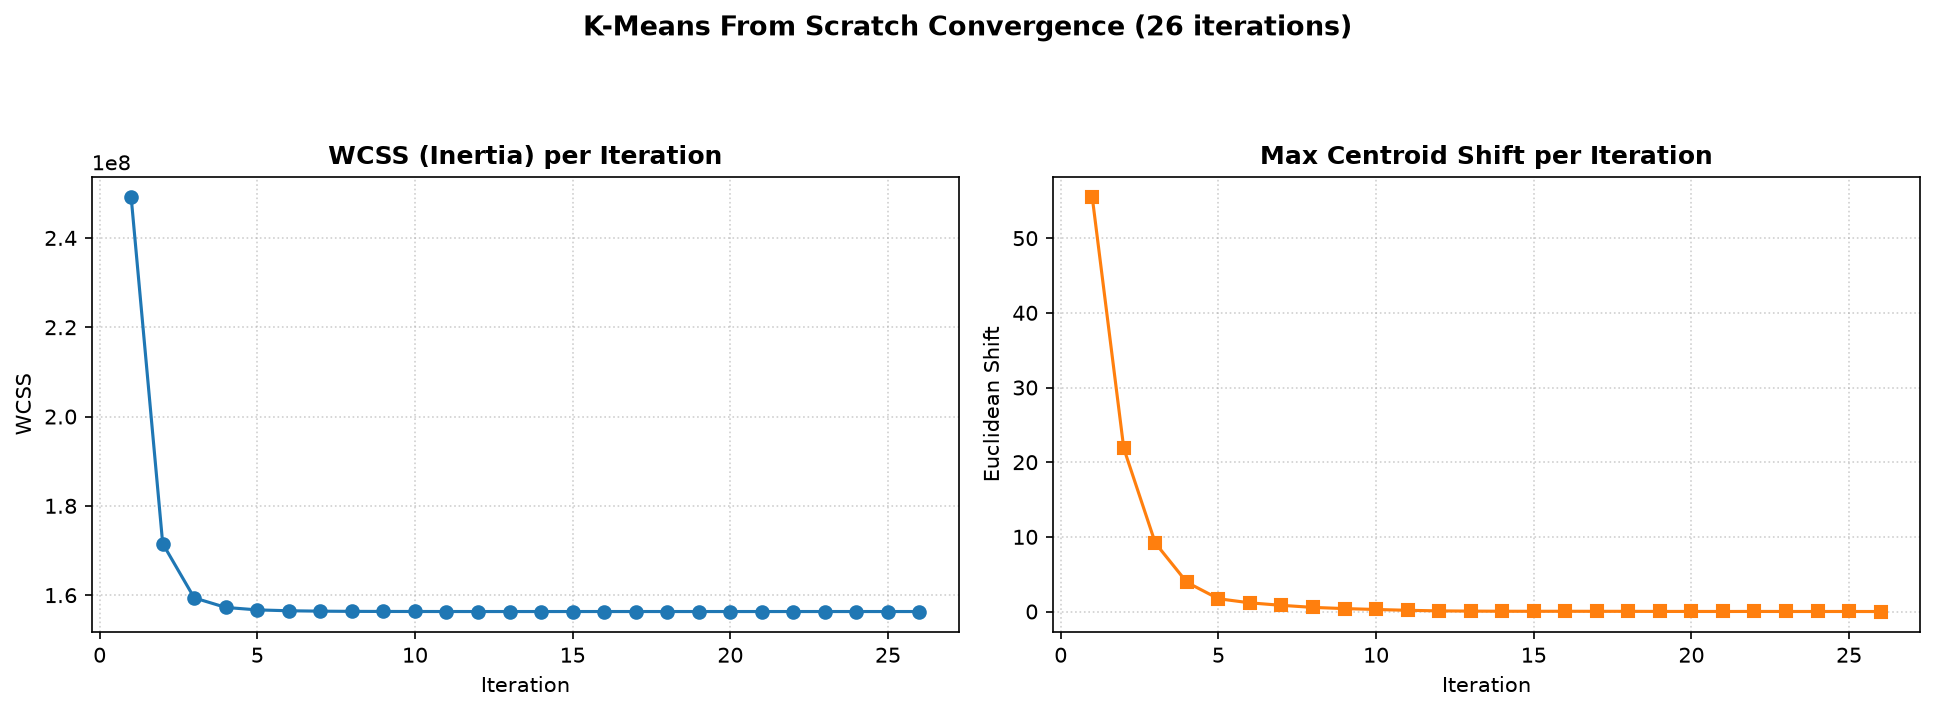

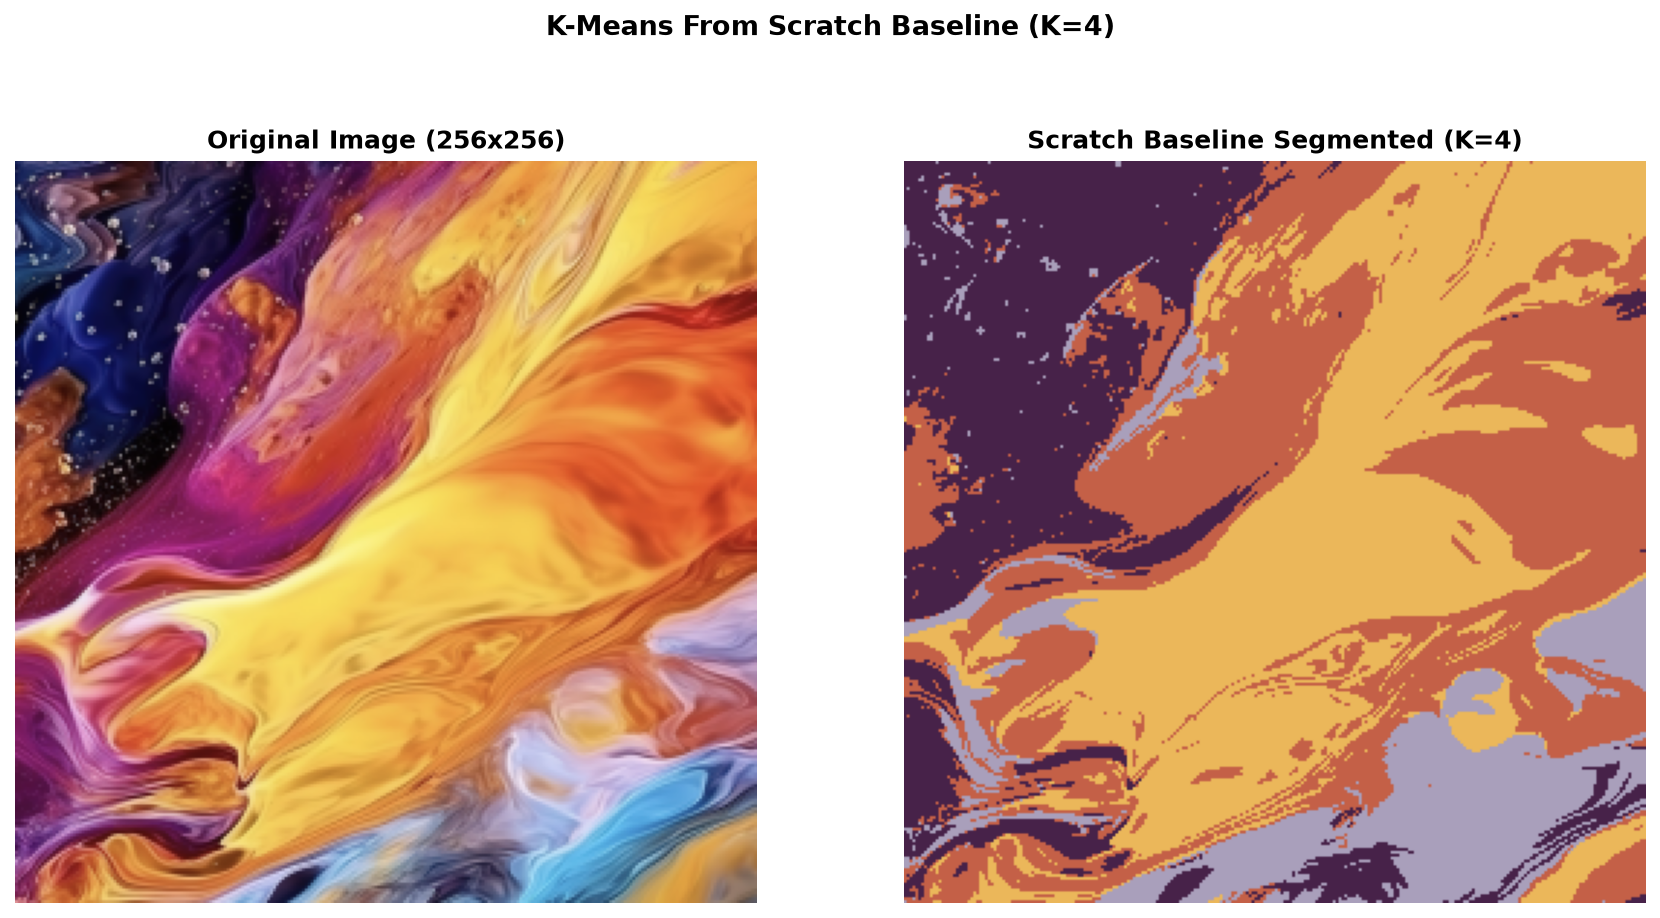

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
axes[0].plot(history_df['iteration'], history_df['inertia'], marker='o', color='#1f77b4')
axes[0].set_title('WCSS (Inertia) per Iteration', fontweight='bold')
axes[0].set_xlabel('Iteration')
axes[0].set_ylabel('WCSS')
axes[0].grid(True, linestyle=':', alpha=0.6)

axes[1].plot(history_df['iteration'], history_df['centroid_shift'], marker='s', color='#ff7f0e')
axes[1].set_title('Max Centroid Shift per Iteration', fontweight='bold')
axes[1].set_xlabel('Iteration')
axes[1].set_ylabel('Euclidean Shift')
axes[1].grid(True, linestyle=':', alpha=0.6)
fig.suptitle(f'K-Means From Scratch Convergence ({len(history_df)} iterations)', fontsize=13, fontweight='bold', y=0.98)
fig.tight_layout(rect=[0.0, 0.0, 1.0, 0.90])
show_figure(fig)

seg_baseline = ImageSegmenter().reconstruct_segmented_image(
    scratch_model.labels_, scratch_model.centroids, target_shape=(new_h, new_w)
)
fig2, ax2 = plt.subplots(1, 2, figsize=(12, 6.2))
ax2[0].imshow(resized_rgb)
ax2[0].set_title(f'Original Image ({new_w}x{new_h})', fontweight='bold')
ax2[0].axis('off')
ax2[1].imshow(seg_baseline)
ax2[1].set_title(f'Scratch Baseline Segmented (K={BASELINE_K})', fontweight='bold')
ax2[1].axis('off')
fig2.suptitle(f'K-Means From Scratch Baseline (K={BASELINE_K})', fontsize=13, fontweight='bold', y=0.98)
fig2.tight_layout(rect=[0.0, 0.0, 1.0, 0.90])
show_figure(fig2)